In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from ipynb.fs.full.preprocessing import process_the_data, read_the_data

<h3> Looking at the steps calculated by DeltabotController

Text(0.5, 0.98, 'Calculated steps in order')

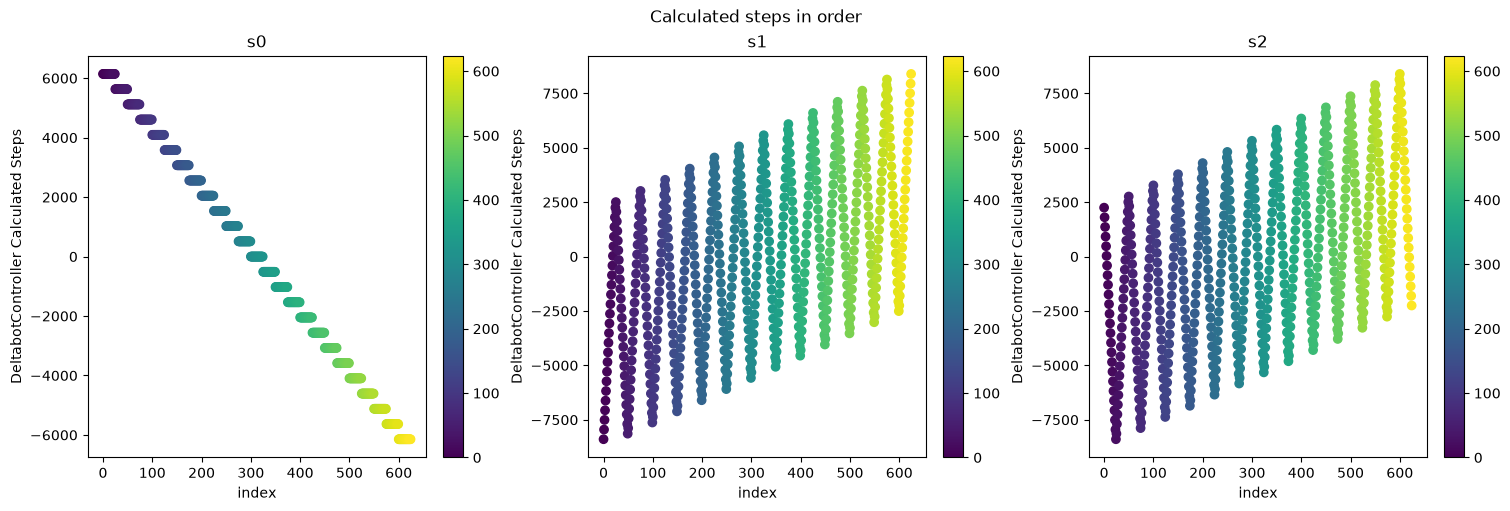

In [3]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor].index, mesh0045_27Oct[motor], c=mesh0045_27Oct.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("DeltabotController Calculated Steps")
    axs[i].set_title(motor)
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Calculated steps in order")

We can see that the s0 value is set for each row and we see the snaking behaviour of the s1 and s2 motors.

Find the max/min values of the motors so we can ensure the predicted values are within sensible limits.

In [4]:
# algorithm_steps
print("Calculated Motor Values Max/Min")
print(max(mesh0045_27Oct["s0"]))
print(max(mesh0045_27Oct["s1"]))
print(max(mesh0045_27Oct["s2"]))
print(min(mesh0045_27Oct["s0"]))
print(min(mesh0045_27Oct["s1"]))
print(min(mesh0045_27Oct["s2"]))

Calculated Motor Values Max/Min
6144.0
8393.0
8393.0
-6144.0
-8393.0
-8393.0


<h1> LR Predictions - Sklearn

In [5]:
#ensuring min and max motor values are sensible
#output
pred_snake_steps = pd.read_csv("predictions/all_data_LR_Pred_snake_mesh.csv", names=["s0", "s1", "s2"], dtype="float32")
display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print("max s0 motor value: ", max(pred_snake_steps["s0"]))
print("max s1 motor value: ", max(pred_snake_steps["s1"]))
print("max s2 motor value: ", max(pred_snake_steps["s2"]))
print("min s0 motor value: ", min(pred_snake_steps["s0"]))
print("min s1 motor value: ", min(pred_snake_steps["s1"]))
print("min s2 motor value: ", min(pred_snake_steps["s2"]))

,s0,s1,s2
0,4516.151367,-5841.085449,1324.935791
1,4487.447754,-5530.404297,1042.958496
2,4458.744629,-5219.723633,760.981262
3,4430.041016,-4909.042969,479.004028
4,4401.337402,-4598.361816,197.026764


Predicted motor values Max/Min
max s0 motor value:  4516.1513671875
max s1 motor value:  6250.97119140625
max s2 motor value:  4954.109375
min s0 motor value:  -4437.623046875
min s1 motor value:  -5841.08544921875
min s2 motor value:  -5442.5185546875


max/min values are within the limits of the algorithm calculated steps. 

Sum of motor values should = 0. Investigate: 

In [6]:
pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print("highest motor sum (no adjustments): ", max(pred_snake_steps["sum_motors"]))
print("lowest motor sum (no adjustments): ", min(pred_snake_steps["sum_motors"]))


highest motor sum (no adjustments):  0.00341796875
lowest motor sum (no adjustments):  0.001708984375


min and max sums are close to 0 - no need to adjust

Plotting predicted values from LR to look at 

Text(0.5, 0.98, 'Predictions from Standard Scaled Linear Regression on all data - Snake Scan')

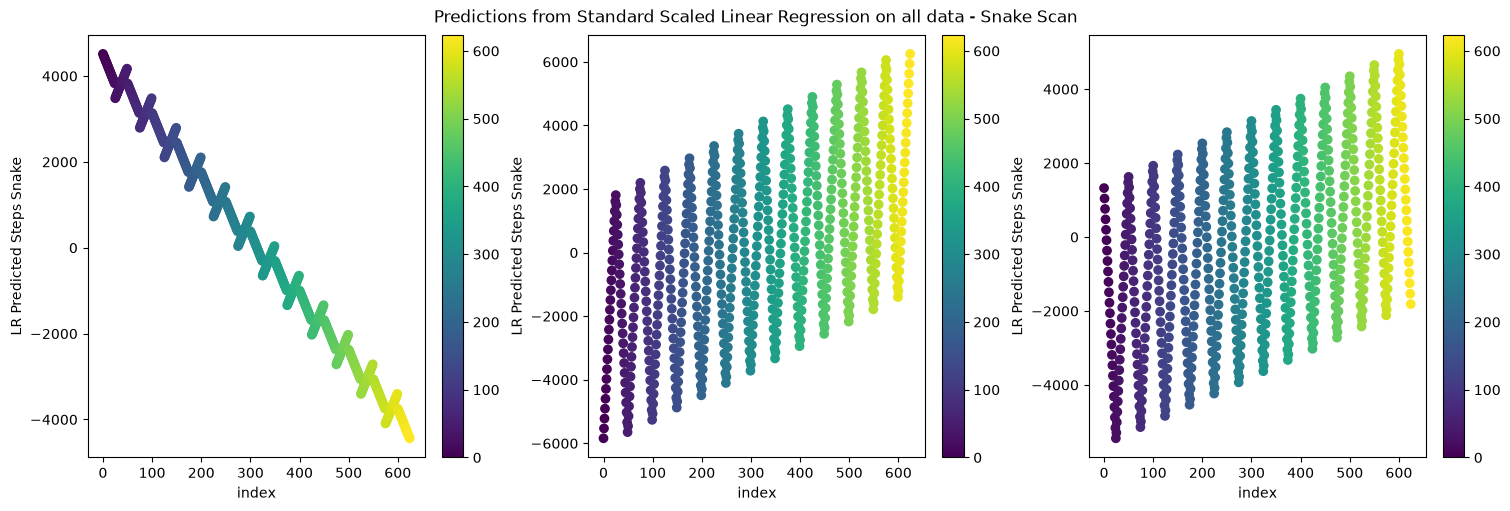

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("LR Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])  
fig.suptitle("Predictions from Standard Scaled Linear Regression on all data - Snake Scan")

<h2> Comparing the 2 datasets

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard Scaled Linear Regression (all data) Predictions for snake scan')

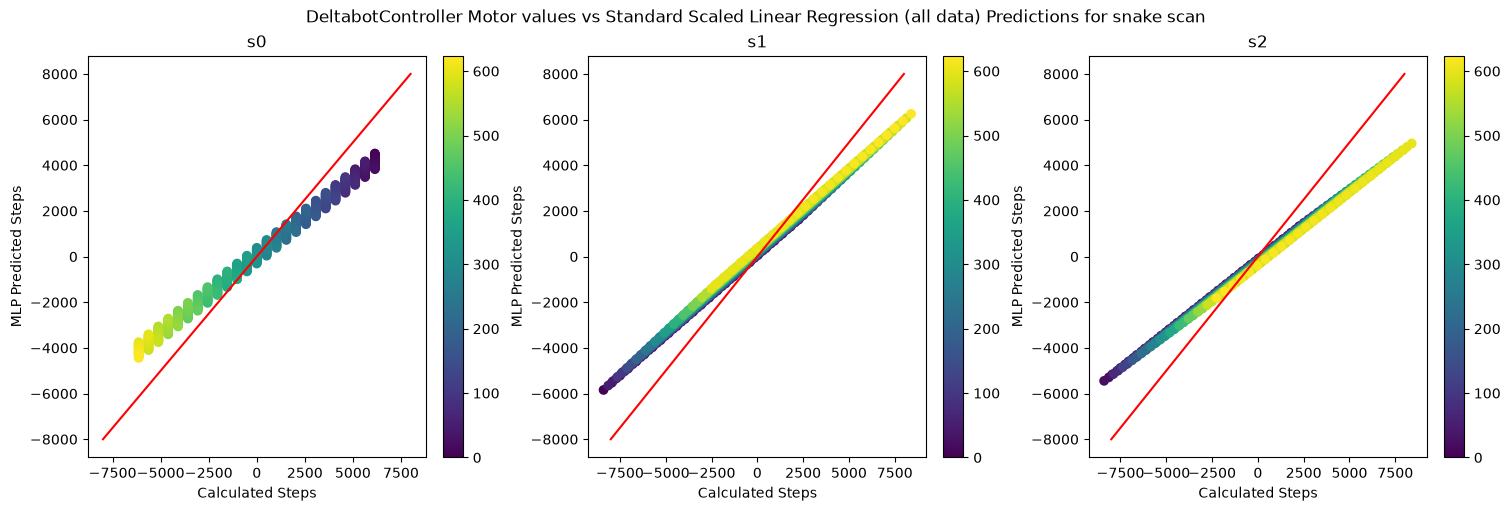

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[motor], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled Linear Regression (all data) Predictions for snake scan")

<h1>Output from Scan using predicted LR motor values

In [9]:
path = "scripts/scans/MLP"
scan = "0015_LR_all"

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 318#px
start_cy = 260 #px

scan_LR = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_LR.name = "scan_LR"

Text(0.5, 1.0, 'all data LR predictions scan')

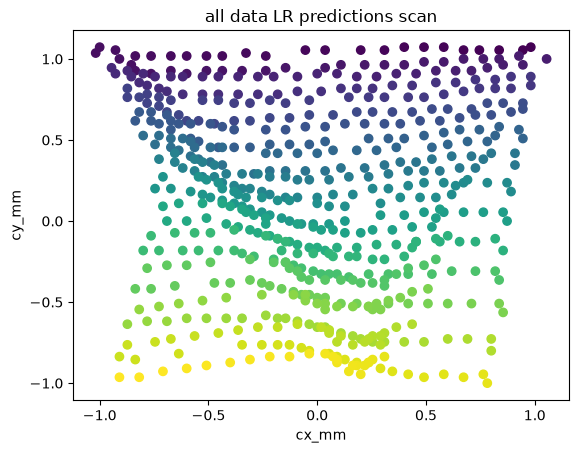

In [10]:
plt.scatter(scan_LR["cx_mm"], scan_LR["cy_mm"], c=scan_LR["point"])
plt.xlabel("cx_mm")
plt.ylabel("cy_mm")
plt.title(f"all data LR predictions scan")

Text(0.5, 0.98, 'Comparing the x-y values, the measured cx and cy from a basic scan and cx and cy from a scan with motor values predicted by Linear Regression')

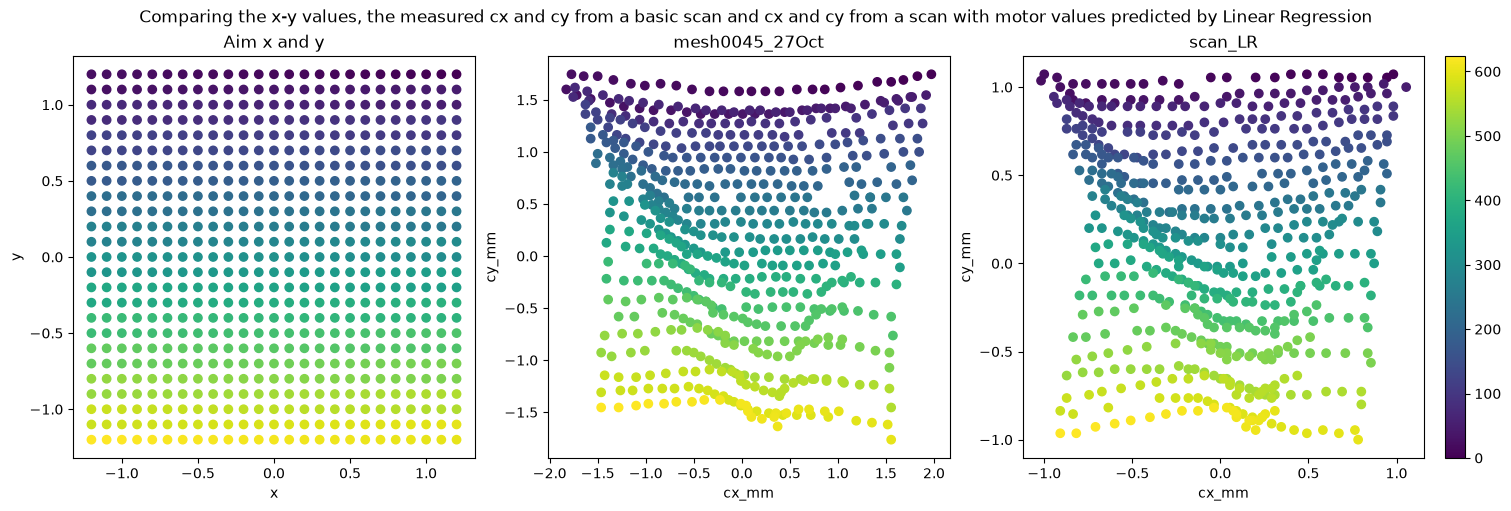

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

im = axs[0].scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Aim x and y")

mesh0045_27Oct.name = "mesh0045_27Oct"
scan_LR.name = "scan_LR"
i = 1
for scan in mesh0045_27Oct, scan_LR:
    suplot = axs[i]
    suplot.scatter(scan["cx_mm"], scan["cy_mm"], c=scan["point"])
    suplot.set_xlabel("cx_mm")
    suplot.set_ylabel("cy_mm")
    # fig.colorbar(im, ax=axs[i])  
    suplot.set_title(scan.name)
    i = i+1

fig.colorbar(im, ax=axs[2])  
fig.suptitle("Comparing the x-y values, the measured cx and cy from a basic scan and cx and cy from a scan with motor values predicted by Linear Regression")

<h1>MLP

In [12]:
#gave those x and y values to the 16Oct MLP 
#output
pred_snake_steps = pd.read_csv("predictions/all_data_MLP_pred_snake.csv", names=["s0", "s1", "s2"], dtype="float32")
display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print(max(pred_snake_steps["s0"]))
print(max(pred_snake_steps["s1"]))
print(max(pred_snake_steps["s2"]))
print(min(pred_snake_steps["s0"]))
print(min(pred_snake_steps["s1"]))
print(min(pred_snake_steps["s2"]))

,s0,s1,s2
0,4958.102051,-4866.446777,35.780846
1,4953.664062,-4646.010254,-191.784195
2,4948.992188,-4439.156738,-388.866486
3,4941.231934,-4230.170898,-580.622681
4,4932.421387,-4020.459717,-770.566528


Predicted motor values Max/Min
5086.2431640625
7320.87451171875
4708.72314453125
-4597.958984375
-4866.44677734375
-5680.70556640625


In [13]:
pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print("highest motor sum (no adjustments): ", max(pred_snake_steps["sum_motors"]))
print("lowest motor sum (no adjustments): ", min(pred_snake_steps["sum_motors"]))


pred_snake_steps["s0_adj"] = pred_snake_steps["s0"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s1_adj"] = pred_snake_steps["s1"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s2_adj"] = pred_snake_steps["s2"] - (pred_snake_steps["sum_motors"]/3)

pred_snake_steps['sum_motors_adj'] = pred_snake_steps["s0_adj"] + pred_snake_steps["s1_adj"] + pred_snake_steps["s2_adj"]
# display(pred_snake_steps['sum_motors'])
print(max(pred_snake_steps["sum_motors_adj"]))
print(min(pred_snake_steps["sum_motors_adj"]))
print(max(pred_snake_steps["s0_adj"]))
print(max(pred_snake_steps["s1_adj"]))
print(max(pred_snake_steps["s2_adj"]))
print(min(pred_snake_steps["s0_adj"]))
print(min(pred_snake_steps["s1_adj"]))
print(min(pred_snake_steps["s2_adj"]))


highest motor sum (no adjustments):  224.9775390625
lowest motor sum (no adjustments):  -11.362060546875
0.00048828125
-0.00048828125
5022.6181640625
7296.42822265625
4634.2197265625
-4603.4326171875
-4908.92529296875
-5717.00146484375


Text(0.5, 0.98, 'Predictions from Standard Scaled MLP on all data - Snake Scan')

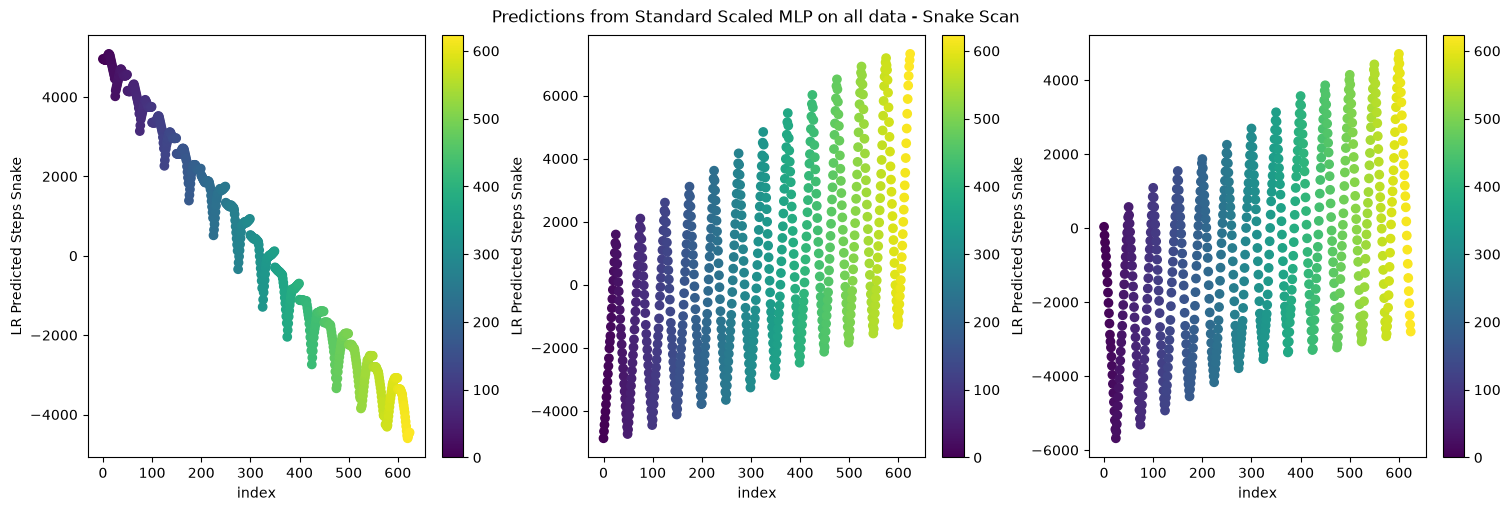

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("LR Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])  
fig.suptitle("Predictions from Standard Scaled MLP on all data - Snake Scan")

Text(0.5, 0.98, 'Predictions from Standard Scaled MLP Snake Scan - motor values adjusted to sum to 0')

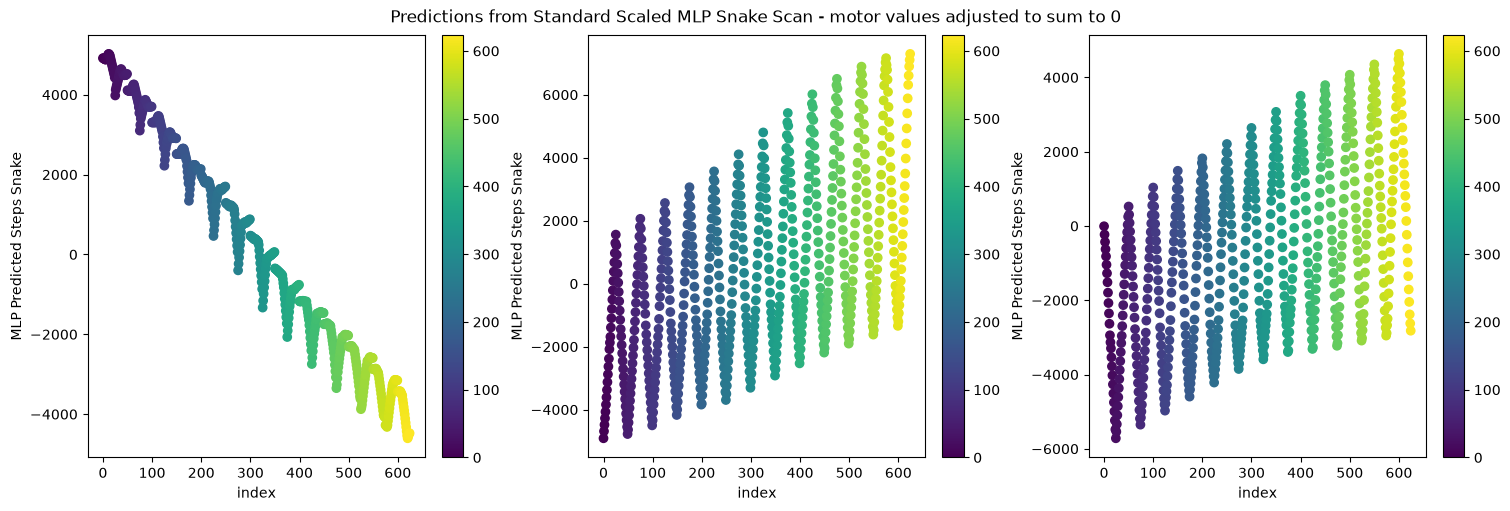

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0_adj", "s1_adj", "s2_adj"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Predictions from Standard Scaled MLP Snake Scan - motor values adjusted to sum to 0")

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan - values adjusted to sum to 0')

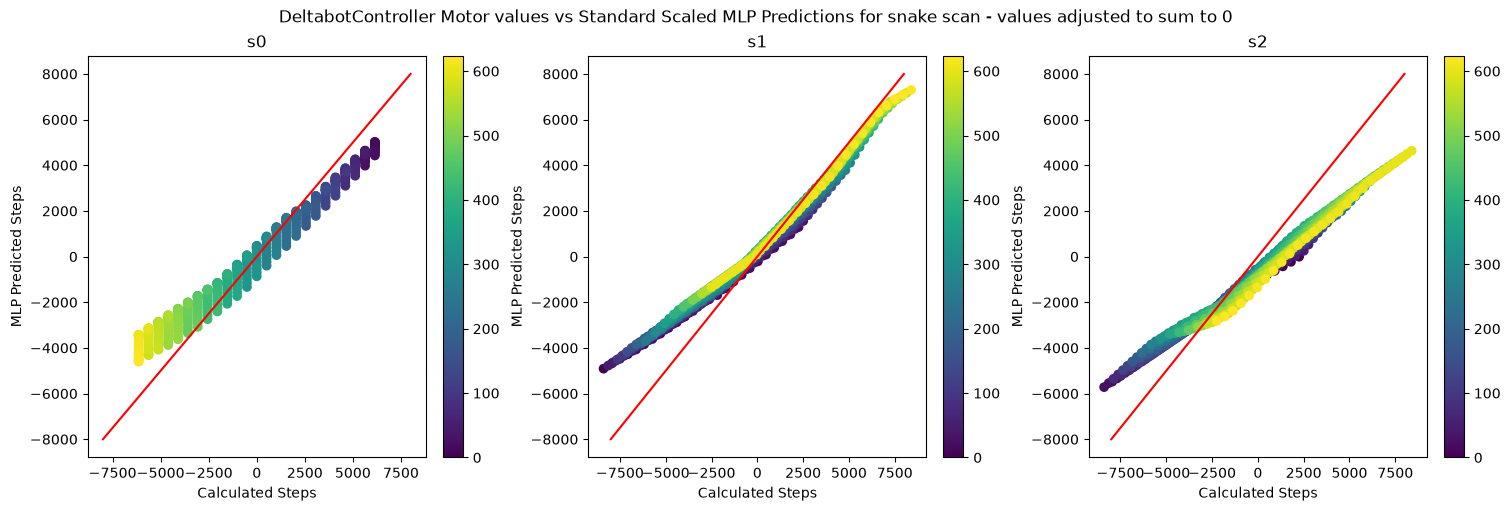

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[f"{motor}_adj"], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan - values adjusted to sum to 0")

In [17]:
pred_snake_steps[["s0_adj", "s1_adj", "s2_adj"]].astype("int32").to_csv("predictions/adjusted_to_sum_to_0/all_data_MLP_adj_snake.csv", index=False)
data = pd.read_csv("predictions/adjusted_to_sum_to_0/all_data_MLP_adj_snake.csv")
# points = list(data.itertuples(index=False, name=None))
# print(points)
# # list(pred_snake_steps.itertuples(index=False, name=None))

<h1> Scan using Basic MLP Predictions

Text(0.5, 1.0, 'all data MLP predictions scan')

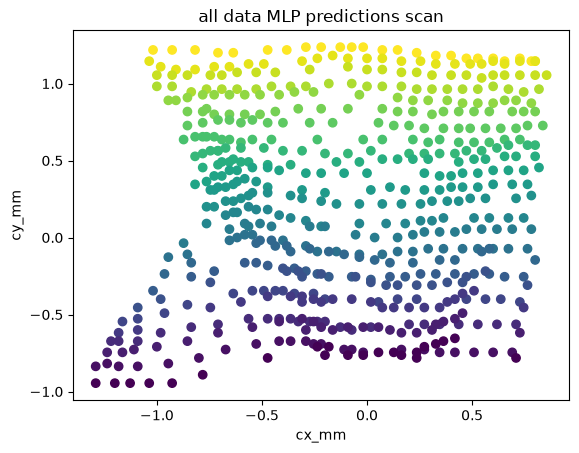

In [18]:
path = "scripts/scans/MLP"
scan = "0018_LR_all" #forgot to change the name

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 320#px
start_cy = 258 #px

scan_MLP = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_MLP.name = "scan_MLP"

plt.scatter(scan_MLP["cx_mm"], scan_MLP["cy_mm"], c=mesh0045_27Oct["y"])
plt.xlabel("cx_mm")
plt.ylabel("cy_mm")
plt.title(f"all data MLP predictions scan")

Text(0.5, 0.98, 'Comparing the x-y values, the measured cx and cy from a basic scan and cx and cy from a scan with motor values predicted by a basic MLP')

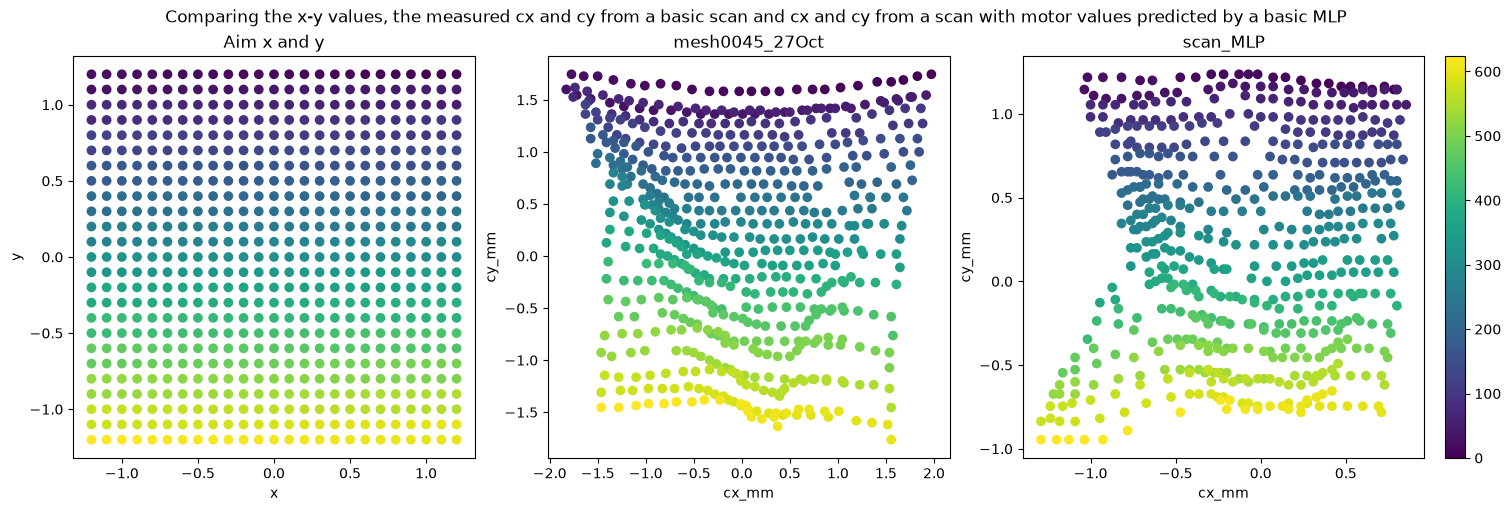

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

im = axs[0].scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Aim x and y")

mesh0045_27Oct.name = "mesh0045_27Oct"
scan_MLP.name = "scan_MLP"
i = 1
for scan in mesh0045_27Oct, scan_MLP:
    suplot = axs[i]
    suplot.scatter(scan["cx_mm"], scan["cy_mm"], c=scan["point"])
    suplot.set_xlabel("cx_mm")
    suplot.set_ylabel("cy_mm")
    # fig.colorbar(im, ax=axs[i])  
    suplot.set_title(scan.name)
    i = i+1

fig.colorbar(im, ax=axs[2])  
fig.suptitle("Comparing the x-y values, the measured cx and cy from a basic scan and cx and cy from a scan with motor values predicted by a basic MLP")

<h1>MLP with </h1>
<h3>
- input window of 10 

- slowed Learning Rate

- calculate s2 from -(s0 + s1)

Predicted motor values Max/Min
max s0 motor value:  4917.8681640625
max s1 motor value:  6901.51220703125
max s2 motor value:  5178.21142578125
min s0 motor value:  -4497.6328125
min s1 motor value:  -5055.03125
min s2 motor value:  -5565.9482421875
highest motor sum (no adjustments):  0.0
lowest motor sum (no adjustments):  0.0


Text(0.5, 0.98, 'DeltabotController Motor values vs Standard Scaled MLP Windowed Predictions for snake scan - values adjusted to sum to 0')

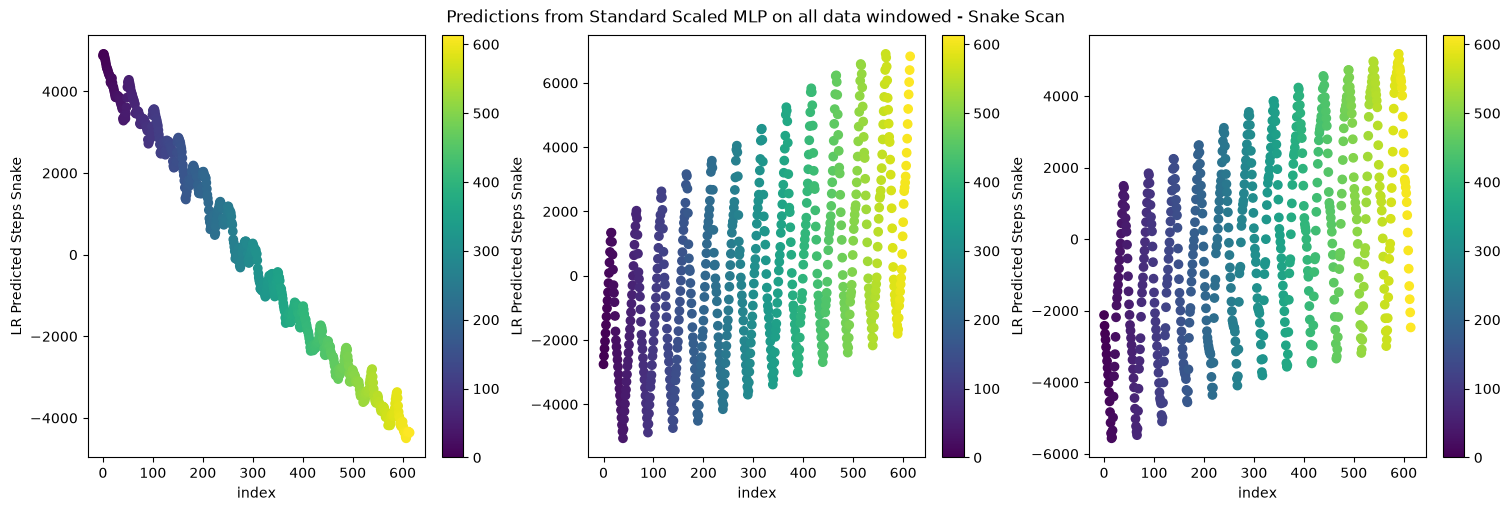

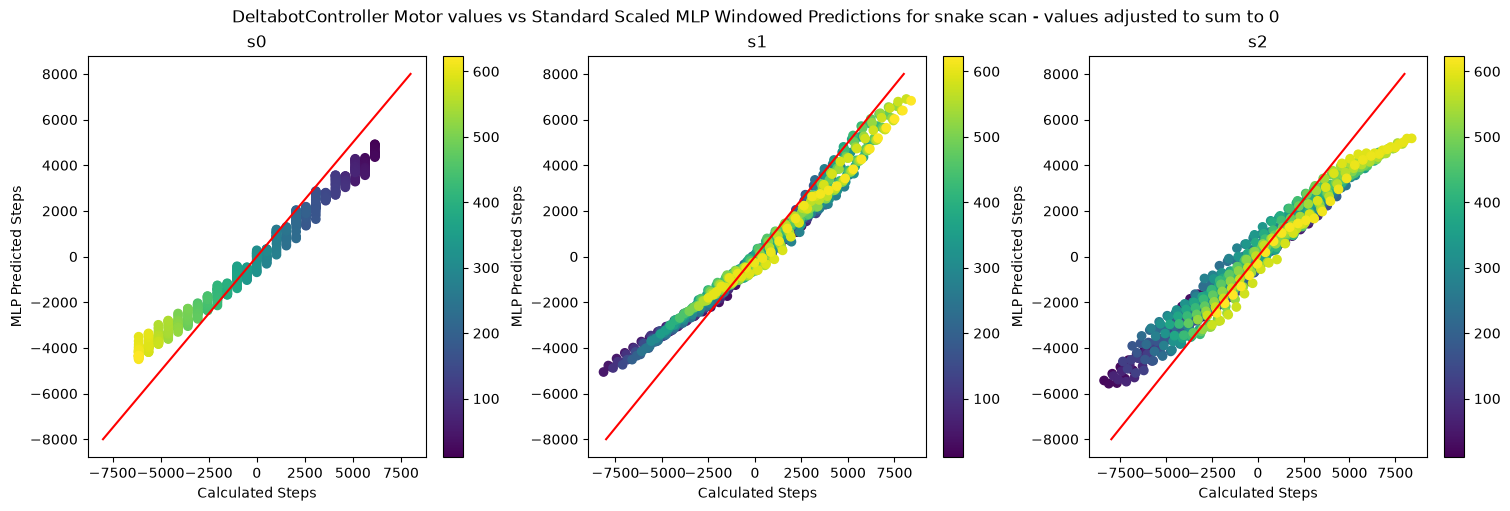

In [20]:
#gave those x and y values to the 16Oct MLP 
#output
pred_snake_steps = pd.read_csv("predictions/all_data_MLP_Window_pred_snake.csv", names=["s0", "s1", "s2"], dtype="float32")
# display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print("max s0 motor value: ", max(pred_snake_steps["s0"]))
print("max s1 motor value: ", max(pred_snake_steps["s1"]))
print("max s2 motor value: ", max(pred_snake_steps["s2"]))
print("min s0 motor value: ", min(pred_snake_steps["s0"]))
print("min s1 motor value: ", min(pred_snake_steps["s1"]))
print("min s2 motor value: ", min(pred_snake_steps["s2"]))

pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print("highest motor sum (no adjustments): ", max(pred_snake_steps["sum_motors"])) #0 as s2 was calculated to ensure this
print("lowest motor sum (no adjustments): ", min(pred_snake_steps["sum_motors"])) #0 as s2 was calculated to ensure this


fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("LR Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])  
fig.suptitle("Predictions from Standard Scaled MLP on all data windowed - Snake Scan")


fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor].iloc[10:], pred_snake_steps[f"{motor}"], c=mesh0045_27Oct["point"].iloc[10:])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled MLP Windowed Predictions for snake scan - values adjusted to sum to 0")

<h1> Scan using MLP Window Predictions

Text(0.5, 1.0, 'all data MLP predictions scan, (not homed properly)')

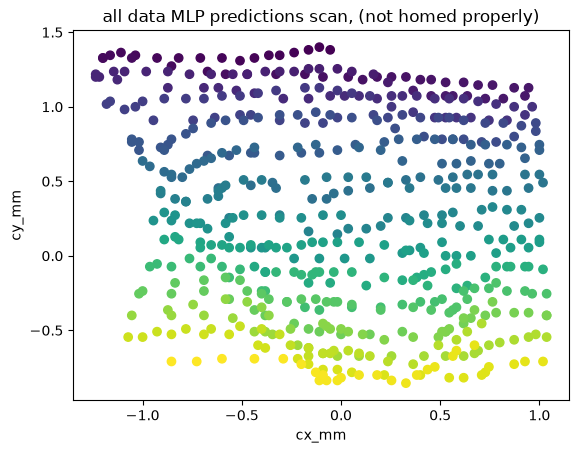

In [21]:
path = "scripts/scans/MLP"
scan = "0021_MLP_Window" #forgot to change the name

x_conversion = 0.1/11
y_conversion = x_conversion

#if considering follow on from basic MLP because I didn't home it
start_cx = 320#px
start_cy = 258 #px

#if considering a new dataset with the measured 0 position
# start_cx = 336#px
# start_cy = 242 #px

scan_MLP_window = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_MLP_window.name = "scan_MLP_window"

plt.scatter(scan_MLP_window["cx_mm"], scan_MLP_window["cy_mm"], c=scan_MLP_window["point"])
plt.xlabel("cx_mm")
plt.ylabel("cy_mm")
plt.title(f"all data MLP predictions scan, (not homed properly)")

Text(0.5, 1.0, 'all data MLP predictions scan, (homed once)')

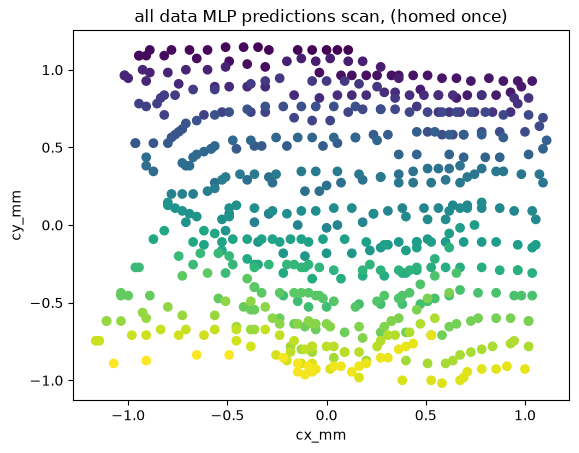

In [22]:
path = "scripts/scans/MLP"
scan = "0024_MLP_Window" #forgot to change the name

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx =  292#px
start_cy =  246#px

scan_MLP_window = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_MLP_window.name = "scan_MLP_window"

plt.scatter(scan_MLP_window["cx_mm"], scan_MLP_window["cy_mm"], c=scan_MLP_window["point"])
plt.xlabel("cx_mm")
plt.ylabel("cy_mm")
plt.title(f"all data MLP predictions scan, (homed once)")

Text(0.5, 0.98, 'Comparing the x-y values, the measured cx and cy from a basic scan and cx and cy from a scan with motor values predicted by an MLP with input = 10-step time window')

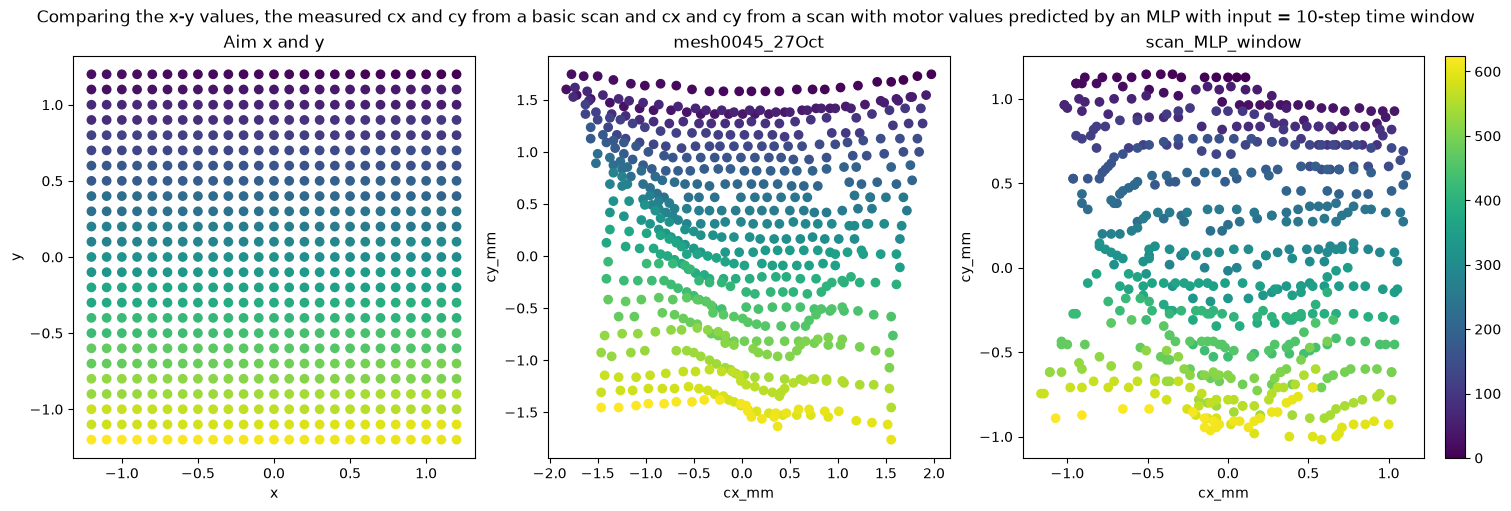

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

im = axs[0].scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Aim x and y")

mesh0045_27Oct.name = "mesh0045_27Oct"
scan_MLP_window.name = "scan_MLP_window"
i = 1
for scan in mesh0045_27Oct, scan_MLP_window:
    suplot = axs[i]
    suplot.scatter(scan["cx_mm"], scan["cy_mm"], c=scan["point"])
    suplot.set_xlabel("cx_mm")
    suplot.set_ylabel("cy_mm")
    # fig.colorbar(im, ax=axs[i])  
    suplot.set_title(scan.name)
    i = i+1

fig.colorbar(im, ax=axs[2])  
fig.suptitle("Comparing the x-y values, the measured cx and cy from a basic scan and cx and cy from a scan with motor values predicted by an MLP with input = 10-step time window")